# Week 4 - Part A: nine charts that are wrong before anything is drawn

Every case below is rebuilt from the recipe first and has to hit the self-check number (each one is an `assert`, so the notebook stops if a rebuild is off).
Then for each one: the conclusion the chart invites, the first objection I thought of and why the data rules it out, the actual mechanism with the number that proves it, and the redesign plotted.

All data is synthetic course data for CDB601220 (Week 4).

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Works both as a notebook (opened from week4/) and as a script (week4/submission/x.py)
try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import tslib
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)

style_defaults()
warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK, SOFT = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]


def src(case):
    return f"Source: synthetic course data, CDB601220 Week 4 ({case}). Chart: Syed Sami Ullah."


def save(fig, name, case):
    save_fig(fig, CHARTS / name, note=src(case))
    show()

---
## Case 1 · "Orders peak in Q1 and collapse every year - a clear annual cycle"
Recipe: sort the 24 rows by `month`, line with markers, y from zero.

{'month': <StringDtype(storage='python', na_value=nan)>, 'orders': dtype('int64'), 'branch': <StringDtype(storage='python', na_value=nan)>}
text-sorted order: ['2024-1', '2024-10', '2024-11', '2024-12', '2024-2', '2024-3', '2024-4', '2024-5', '2024-6', '2024-7', '2024-8', '2024-9', '2025-1', '2025-10', '2025-11', '2025-12', '2025-2', '2025-3', '2025-4', '2025-5', '2025-6', '2025-7', '2025-8', '2025-9']
drops: [-958, -978]


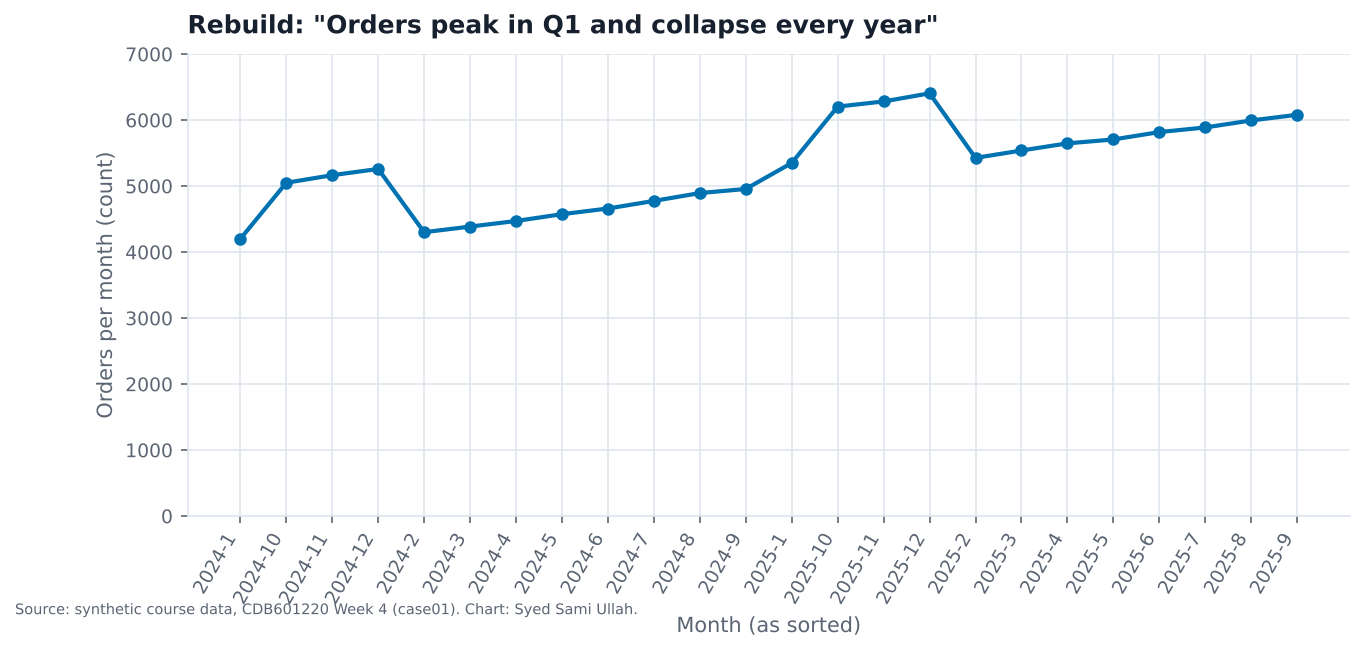

In [2]:
c1 = pd.read_csv(DATA / "case01_orders_stringdate.csv")
print(c1.dtypes.to_dict())
rb = c1.sort_values("month").reset_index(drop=True)      # the analyst's sort - on text
steps = rb.orders.diff().dropna().astype(int)

assert len(rb) == 24
assert steps.min() == -978 and (steps == -958).sum() == 1
assert (steps.iloc[:3] > 0).all() and steps.iloc[3] == -958 and (steps.iloc[4:15] > 0).all() and steps.iloc[15] == -978
print("text-sorted order:", rb.month.tolist())
print("drops:", steps[steps < 0].tolist())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(rb)), rb.orders, color=BLUE, marker="o")
ax.set_xticks(range(len(rb)))
ax.set_xticklabels(rb.month, rotation=60, ha="right")
ax.set_ylim(0, 7000)
ax.set_xlabel("Month (as sorted)")
ax.set_ylabel("Orders per month (count)")
ax.set_title('Rebuild: "Orders peak in Q1 and collapse every year"')
save(fig, "partA_case01_rebuild.png", "case01")

**What this chart shows.** Two drops of 958 and 978 orders that look like a yearly crash after Q1. But the x axis reads 2024-1, 2024-10, 2024-11, 2024-12, 2024-2 ... so the months are in the wrong order to begin with.

In [3]:
print("branches in file:", c1.branch.unique().tolist())
c1["date"] = pd.to_datetime(c1.month, format="%Y-%m")
real = c1.sort_values("date").reset_index(drop=True)
real_steps = real.orders.diff().dropna()
print(f"month-on-month changes in real order: min {real_steps.min():+.0f}, max {real_steps.max():+.0f}, negatives = {(real_steps < 0).sum()}")
moved = (rb.month.values != real.month.values).sum()
print(f"rows sitting in the wrong position after the text sort: {moved} of 24")
print(f"Oct-Dec rows pulled in front of Feb: {c1.month.str.match(r'\d{4}-1[0-2]$').sum()}")
print(f"real growth: {real.orders.iloc[0]:,} -> {real.orders.iloc[-1]:,} ({real.orders.iloc[-1] / real.orders.iloc[0] - 1:+.1%})")

branches in file: ['Gulberg']
month-on-month changes in real order: min +59, max +124, negatives = 0
rows sitting in the wrong position after the text sort: 22 of 24
Oct-Dec rows pulled in front of Feb: 6
real growth: 4,200 -> 6,405 (+52.5%)


- **Conclusion it invites:** orders run in a yearly cycle, peaking in Q1 and crashing straight after.
- **Decoy:** my first thought was two branches mixed into one series. Ruled out: `branch` has one value (Gulberg) in all 24 rows.
- **Mechanism:** `month` is text written `YYYY-M` with no zero padding, so the sort is alphabetical. "2024-10", "2024-11", "2024-12" sort before "2024-2", and 22 of the 24 rows end up in the wrong place. Both drops are just December being followed by February: 5,259 → 4,301 (−958) and 6,405 → 5,427 (−978). Parsed as real dates, all 23 monthly changes are positive (smallest +59).

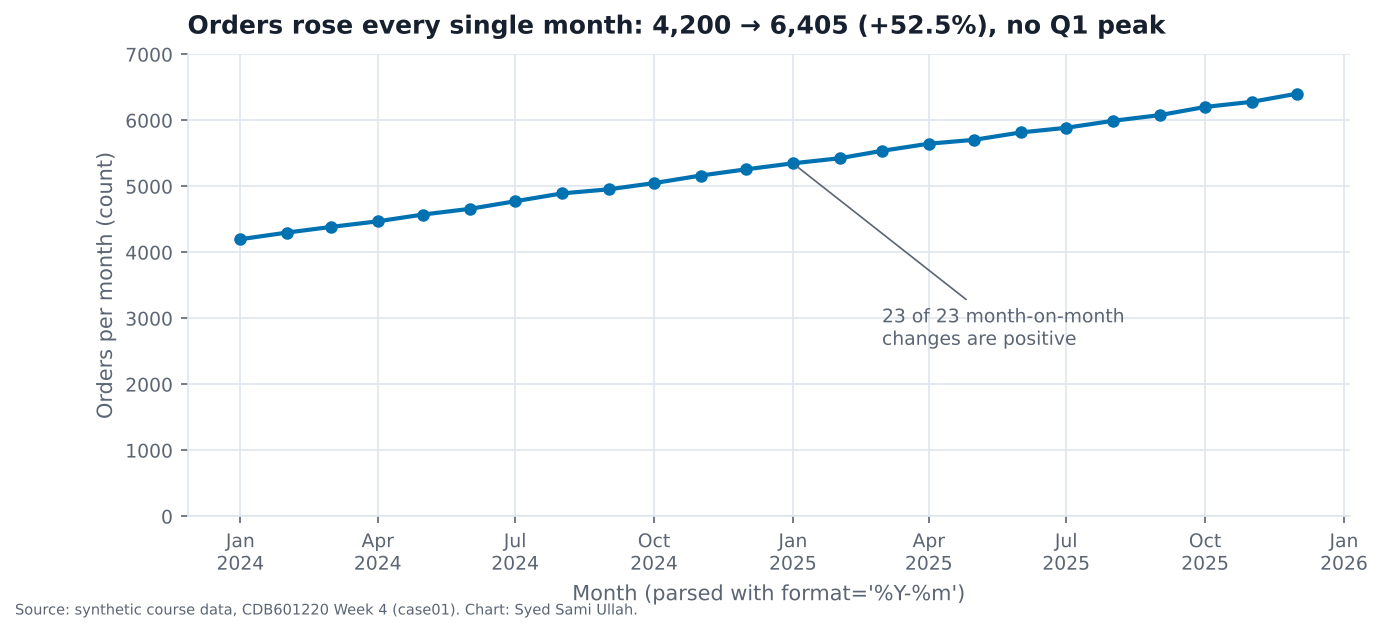

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(real.date, real.orders, color=BLUE, marker="o")
ax.set_ylim(0, 7000)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.set_ylabel("Orders per month (count)")
ax.set_xlabel("Month (parsed with format='%Y-%m')")
ax.set_title("Orders rose every single month: 4,200 → 6,405 (+52.5%), no Q1 peak")
ax.annotate("23 of 23 month-on-month\nchanges are positive", xy=(real.date.iloc[12], real.orders.iloc[12]),
            xytext=(real.date.iloc[14], 2600), color=SOFT, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=SOFT, lw=0.8))
save(fig, "partA_case01_redesign.png", "case01")

**What the redesign shows.** With the dates parsed, the "collapse" disappears and it is a plain steady climb. There is no annual cycle in this file at all.

---
## Case 2 · "Sales grew steadily, 22%, across the quarter"
Recipe: plot `sales_pkr_k` against the row number, add a least-squares trend line.

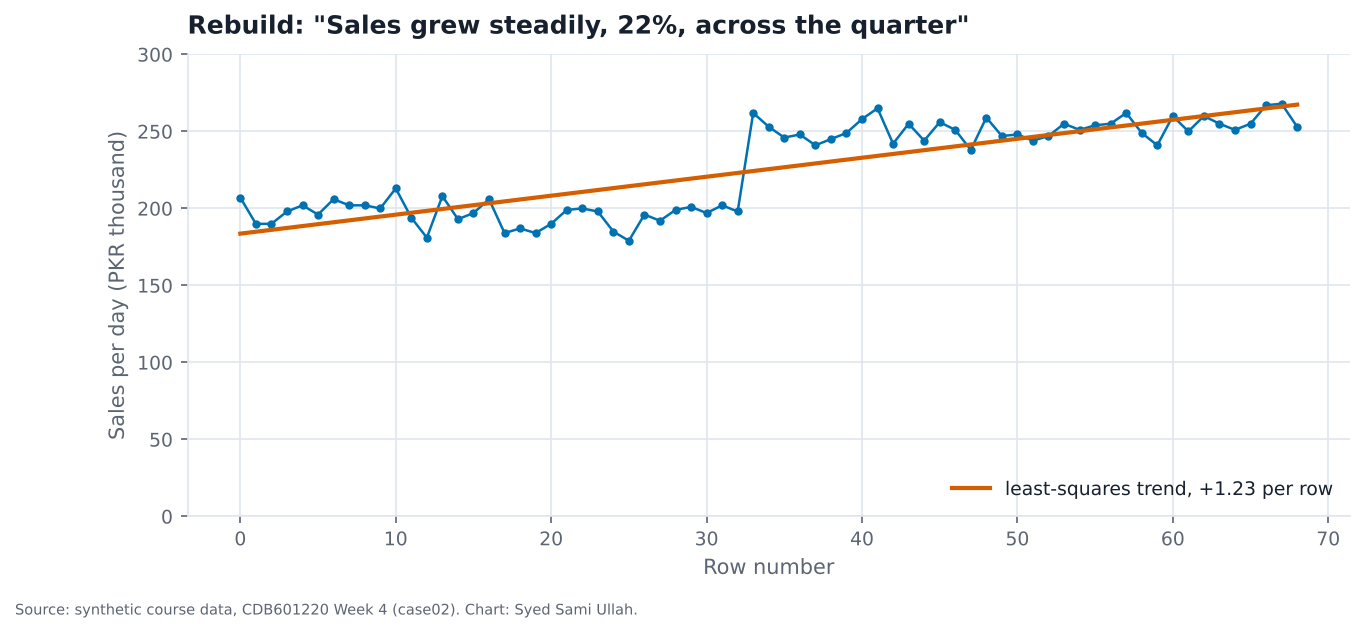

In [5]:
c2 = pd.read_csv(DATA / "case02_shop_closed.csv", parse_dates=["date"])
x = np.arange(len(c2))
slope, icpt = np.polyfit(x, c2.sales_pkr_k, 1)
first, last = c2.sales_pkr_k.iloc[0], c2.sales_pkr_k.iloc[-1]

assert len(c2) == 69 and first == 207 and last == 253
assert round((last / first - 1) * 100) == 22

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, c2.sales_pkr_k, color=BLUE, marker="o", markersize=3, lw=1.2)
ax.plot(x, icpt + slope * x, color=ORANGE, lw=2, label=f"least-squares trend, +{slope:.2f} per row")
ax.set_ylim(0, 300)
ax.set_xlabel("Row number")
ax.set_ylabel("Sales per day (PKR thousand)")
ax.set_title('Rebuild: "Sales grew steadily, 22%, across the quarter"')
ax.legend(loc="lower right")
save(fig, "partA_case02_rebuild.png", "case02")

**What this chart shows.** A smooth upward trend line through 69 points, first 207 and last 253 (+22%). Nothing on it tells you how much time each step on the x axis is.

In [6]:
span = (c2.date.max() - c2.date.min()).days + 1
print(f"len(df) = {len(c2)} rows, date span = {span} days -> {span - len(c2)} days never recorded")
print("rows per weekday:", c2.date.dt.day_name().str[:3].value_counts().reindex(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]).to_dict())
print("mean per weekday:", c2.groupby(c2.date.dt.dayofweek).sales_pkr_k.mean().round(1).tolist())
gap = c2.date.diff().dt.days
print("the gap:", c2.date[gap.idxmax() - 1].date(), "->", c2.date[gap.idxmax()].date(), f"({int(gap.max()) - 1} days missing)")
pre = c2[c2.date < "2025-02-03"]
post = c2[c2.date > "2025-02-23"]
for name, part in [("before", pre), ("after", post)]:
    d = (part.date - part.date.min()).dt.days
    print(f"{name}: n={len(part)}, mean {part.sales_pkr_k.mean():.1f}, slope {np.polyfit(d, part.sales_pkr_k, 1)[0]:+.2f} per day")
print(f"step at reopening: {pre.sales_pkr_k.mean():.1f} -> {post.sales_pkr_k.mean():.1f} ({post.sales_pkr_k.mean() / pre.sales_pkr_k.mean() - 1:+.1%})")

len(df) = 69 rows, date span = 90 days -> 21 days never recorded
rows per weekday: {'Mon': 10, 'Tue': 9, 'Wed': 10, 'Thu': 10, 'Fri': 10, 'Sat': 10, 'Sun': 10}
mean per weekday: [226.9, 231.9, 224.5, 225.4, 222.4, 223.8, 224.3]
the gap: 2025-02-02 -> 2025-02-24 (21 days missing)
before: n=33, mean 196.2, slope -0.16 per day
after: n=36, mean 252.3, slope +0.23 per day
step at reopening: 196.2 -> 252.3 (+28.6%)


- **Conclusion it invites:** the shop grew a little every day through the quarter.
- **Decoy:** "only trading days are recorded" sounds like the weekends are missing, which would be harmless. Ruled out: every weekday appears 9-10 times and the weekday means sit between 222 and 232, so no weekday is closed.
- **Mechanism:** plotting against the row number deletes time. 69 rows cover a 90-day span, and the 21 missing days are one block, 3-23 February, when the shop was shut. Inside each part the trend is flat (−0.16 and +0.23 per day). The whole "+22%" is one step at reopening, 196 → 252 (+28.6%), which the row axis smears into a slope.

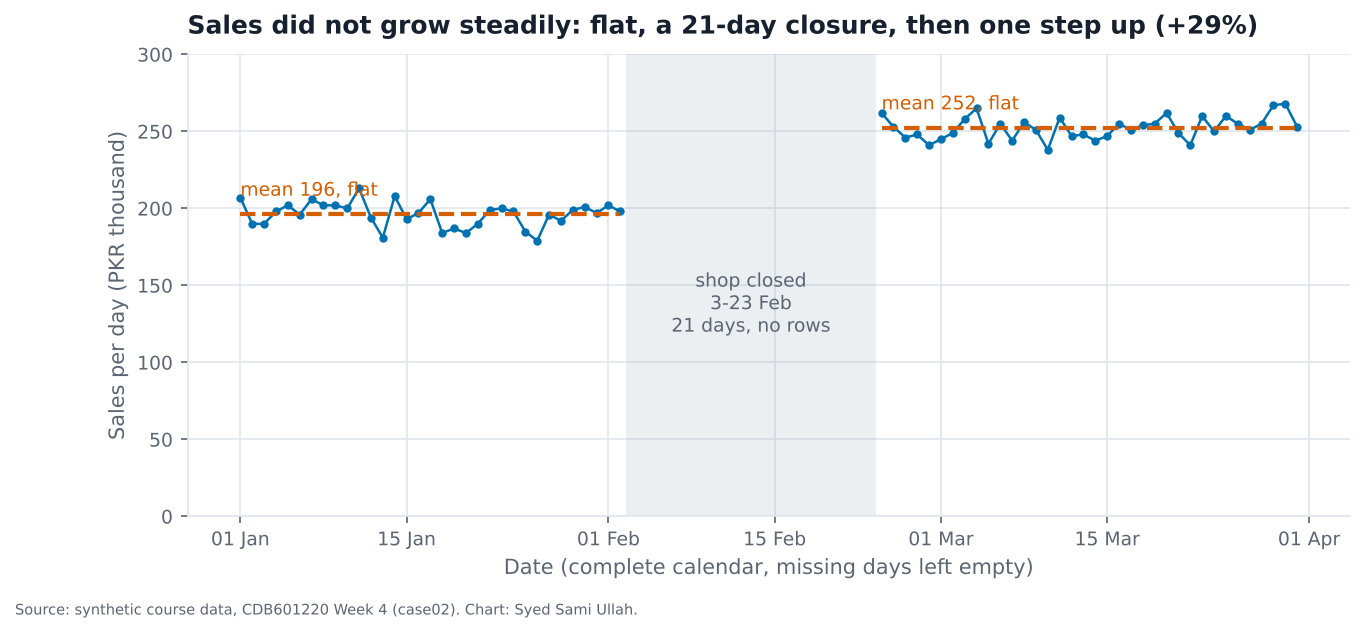

In [7]:
c2_full = c2.set_index("date").sales_pkr_k.pipe(tslib.reindex_full, "D")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(c2_full.index, c2_full, color=BLUE, marker="o", markersize=3, lw=1.2)
ax.axvspan(pd.Timestamp("2025-02-02 12:00"), pd.Timestamp("2025-02-23 12:00"), color=GREY, alpha=0.18, lw=0)
ax.text(pd.Timestamp("2025-02-13"), 120, "shop closed\n3-23 Feb\n21 days, no rows", ha="center", color=SOFT, fontsize=9)
ax.hlines(pre.sales_pkr_k.mean(), pre.date.min(), pre.date.max(), color=ORANGE, lw=2, ls="--")
ax.hlines(post.sales_pkr_k.mean(), post.date.min(), post.date.max(), color=ORANGE, lw=2, ls="--")
ax.text(pre.date.min(), pre.sales_pkr_k.mean() + 12, f"mean {pre.sales_pkr_k.mean():.0f}, flat", color=ORANGE, fontsize=9)
ax.text(post.date.min(), post.sales_pkr_k.mean() + 12, f"mean {post.sales_pkr_k.mean():.0f}, flat", color=ORANGE, fontsize=9)
ax.set_ylim(0, 300)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_xlabel("Date (complete calendar, missing days left empty)")
ax.set_ylabel("Sales per day (PKR thousand)")
ax.set_title("Sales did not grow steadily: flat, a 21-day closure, then one step up (+29%)")
save(fig, "partA_case02_redesign.png", "case02")

**What the redesign shows.** On a real calendar the closure is visible as a hole, and both sides of it are flat. Whatever caused the jump happened during the closure (a refit, a new menu), not gradually across the quarter.

---
## Case 3 · "Peak load jumped 43% overnight on 1 July"
Recipe: resample `concurrent_users` to daily with `.sum()`, line, y from zero.

June 8,782, July 12,543, +42.8%


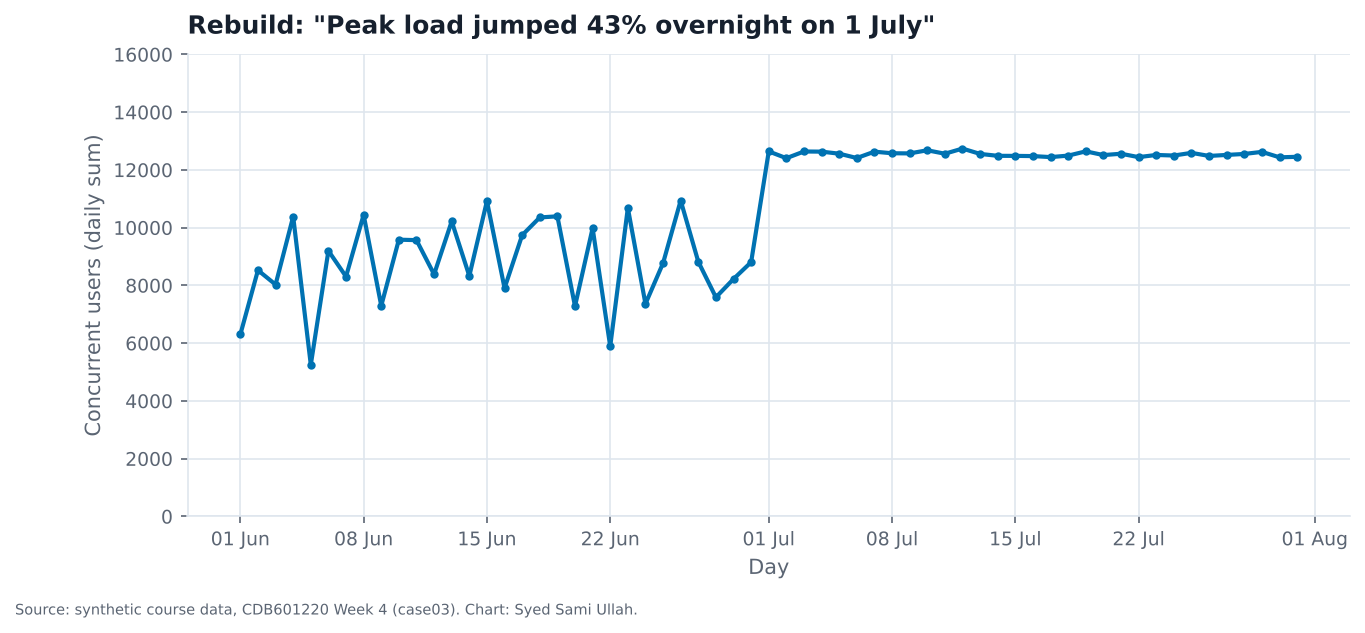

In [8]:
c3 = pd.read_csv(DATA / "case03_bandwidth_levels.csv", parse_dates=["ts"]).set_index("ts")
daily_sum = c3.concurrent_users.resample("D").sum()
jun, jul = daily_sum["2025-06"].mean(), daily_sum["2025-07"].mean()

assert abs(jun - 8800) < 100 and abs(jul - 12500) < 100
assert round((jul / jun - 1) * 100) == 43
print(f"June {jun:,.0f}, July {jul:,.0f}, {jul / jun - 1:+.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_sum.index, daily_sum, color=BLUE, marker="o", markersize=3)
ax.set_ylim(0, 16000)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Concurrent users (daily sum)")
ax.set_xlabel("Day")
ax.set_title('Rebuild: "Peak load jumped 43% overnight on 1 July"')
save(fig, "partA_case03_rebuild.png", "case03")

**What this chart shows.** A clear step from about 8,800 to 12,500 on 1 July. The y label is the giveaway though: a "sum of concurrent users" is not a number of anything.

In [9]:
a3 = tslib.audit_index(c3, "h")
print({k: a3[k] for k in ["dtype_ok", "monotonic", "n_rows", "n_duplicated", "n_missing"]})
hrs = c3.groupby(c3.index.month).size()
print(f"hours recorded: June {hrs[6]} of 720 ({hrs[6] / 720:.1%}, {hrs[6] / 30:.1f} per day), July {hrs[7]} of 744")
bph = c3.bytes_served.groupby(c3.index.month).mean()
print(f"bytes served per recorded hour: June {bph[6]:,.0f}, July {bph[7]:,.0f} ({bph[7] / bph[6] - 1:+.1%})")
dmean = c3.concurrent_users.resample("D").mean()
dmax = c3.concurrent_users.resample("D").max()
print(f"daily MEAN users: June {dmean['2025-06'].mean():.0f}, July {dmean['2025-07'].mean():.0f} ({dmean['2025-07'].mean() / dmean['2025-06'].mean() - 1:+.1%})")
print(f"daily MAX users:  June {dmax['2025-06'].mean():.0f}, July {dmax['2025-07'].mean():.0f} ({dmax['2025-07'].mean() / dmax['2025-06'].mean() - 1:+.1%})")
print(f"hours ratio July/June per day: {24 / (hrs[6] / 30):.2f}")

{'dtype_ok': True, 'monotonic': True, 'n_rows': 1237, 'n_duplicated': 0, 'n_missing': 227}
hours recorded: June 493 of 720 (68.5%, 16.4 per day), July 744 of 744
bytes served per recorded hour: June 1,061,932, July 1,037,295 (-2.3%)
daily MEAN users: June 536, July 523 (-2.5%)
daily MAX users:  June 779, July 808 (+3.7%)
hours ratio July/June per day: 1.46


- **Conclusion it invites:** something on 1 July (a launch, a campaign) pushed peak load up 43% overnight.
- **Decoy:** `bytes_served` also jumps in July, so the traffic looks real. Ruled out: bytes per *recorded* hour are about the same both months (June 1.06m, July 1.04m, −2.3%), so the flow did not rise either.
- **Mechanism:** `concurrent_users` is a level (users online at an instant) and it was resampled with `sum()`. A sum of a level just counts how many readings there were. June has only 493 of 720 hours (16.4 a day) while July has all 744, and 24 / 16.4 = 1.46, which is the whole "+43%". The proper daily mean actually fell 2.5% and the daily peak rose only 3.7%.

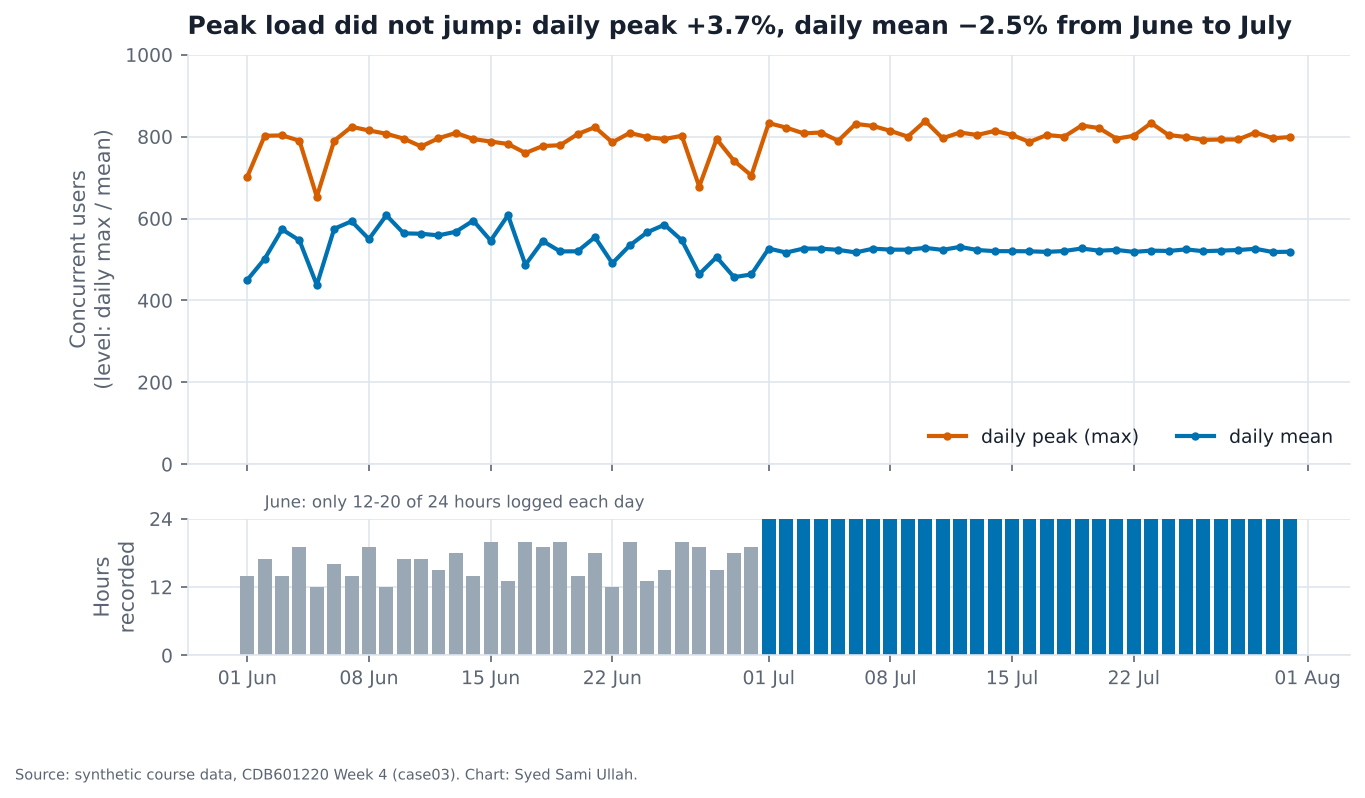

In [10]:
per_day = c3.groupby(c3.index.normalize()).size()
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(dmax.index, dmax, color=ORANGE, marker="o", markersize=3, label="daily peak (max)")
ax.plot(dmean.index, dmean, color=BLUE, marker="o", markersize=3, label="daily mean")
ax.set_ylim(0, 1000)
ax.set_ylabel("Concurrent users\n(level: daily max / mean)")
ax.legend(loc="lower right", ncol=2)
ax.set_title("Peak load did not jump: daily peak +3.7%, daily mean −2.5% from June to July")
ax2.bar(per_day.index, per_day, color=np.where(per_day < 24, GREY, BLUE), width=0.8)
ax2.set_ylim(0, 24)
ax2.set_yticks([0, 12, 24])
ax2.set_ylabel("Hours\nrecorded")
ax2.text(pd.Timestamp("2025-06-02"), 26, "June: only 12-20 of 24 hours logged each day", color=SOFT, fontsize=8)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
save(fig, "partA_case03_redesign.png", "case03")

**What the redesign shows.** Aggregated the way a level should be (mean and max), the load is flat across 1 July. The bottom strip shows the real change on that date: the logger started recording all 24 hours.

---
## Case 4 · "The new checkout flow started working on 7 September"
Recipe: raw `conversion_pct` in grey, 31-day **trailing** mean on top, read the turning point off it.

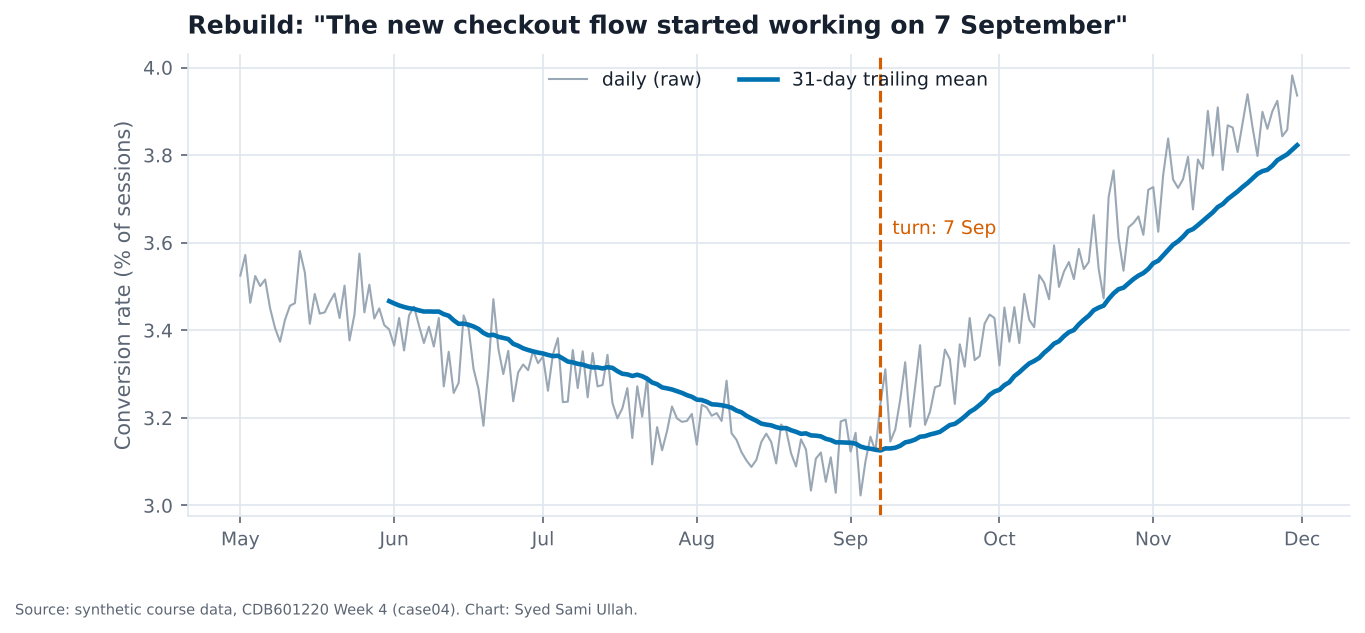

In [11]:
c4 = pd.read_csv(DATA / "case04_intervention_lag.csv", parse_dates=["date"]).set_index("date").conversion_pct
trail = c4.rolling(31).mean()
turn_t = trail.idxmin()
assert turn_t == pd.Timestamp("2025-09-07")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(c4.index, c4, color=GREY, lw=1, label="daily (raw)")
ax.plot(trail.index, trail, color=BLUE, lw=2.2, label="31-day trailing mean")
ax.axvline(turn_t, color=ORANGE, lw=1.5, ls="--")
ax.text(turn_t, 3.62, "  turn: 7 Sep", color=ORANGE, fontsize=9)
ax.set_ylabel("Conversion rate (% of sessions)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title('Rebuild: "The new checkout flow started working on 7 September"')
ax.legend(loc="upper center", ncol=2)
save(fig, "partA_case04_rebuild.png", "case04")

**What this chart shows.** The smoothed line bottoms out on 7 September, and the analyst reads that as the day the new flow started helping. The line is drawn at the *end* of each 31-day window, which the chart doesn't say.

In [12]:
lag = tslib.lag_at_turn(c4, 31, how="min")
print({k: (str(v.date()) if hasattr(v, "date") else v) for k, v in lag.items()})

# independent check on the raw data: best single-breakpoint (hinge) regression
xx = np.arange(len(c4)); best = None
for k in range(20, len(c4) - 20):
    A = np.c_[np.ones(len(xx)), np.minimum(xx - k, 0), np.maximum(xx - k, 0)]
    coef, res, *_ = np.linalg.lstsq(A, c4.values, rcond=None)
    sse = ((A @ coef - c4.values) ** 2).sum()
    if best is None or sse < best[0]:
        best = (sse, k, coef)
hinge = c4.index[best[1]]
print(f"hinge fit on raw data: break at {hinge.date()}, slope before {best[2][1]:+.4f} pp/day, after {best[2][2]:+.4f} pp/day")
print(f"7-day trailing mean bottoms at {c4.rolling(7).mean().idxmin().date()}, 7-day centred at {c4.rolling(7, center=True).mean().idxmin().date()}")

{'window': 31, 'trailing_turn': '2025-09-07', 'centred_turn': '2025-08-23', 'lag_periods': 15, 'half_window': 15}
hinge fit on raw data: break at 2025-08-28, slope before -0.0035 pp/day, after +0.0092 pp/day
7-day trailing mean bottoms at 2025-08-29, 7-day centred at 2025-08-26


- **Conclusion it invites:** the new checkout began lifting conversion on 7 September.
- **Decoy:** "a 31-day mean is so smooth the turn could just be noise." Ruled out: a breakpoint regression on the *raw* data finds a real turn (slope −0.0035 → +0.0092 pp/day). The turn is real, but the date is wrong.
- **Mechanism:** a trailing mean puts each average on the last day of its window, so it cannot see a turn until the window has filled with post-turn days. `lag_at_turn` gives 15 days, exactly half the window: centred minimum 23 August, trailing minimum 7 September. The raw hinge fit puts the break on 28 August. Either way, the flow started working in the last week of August, about two weeks before the date on the chart.

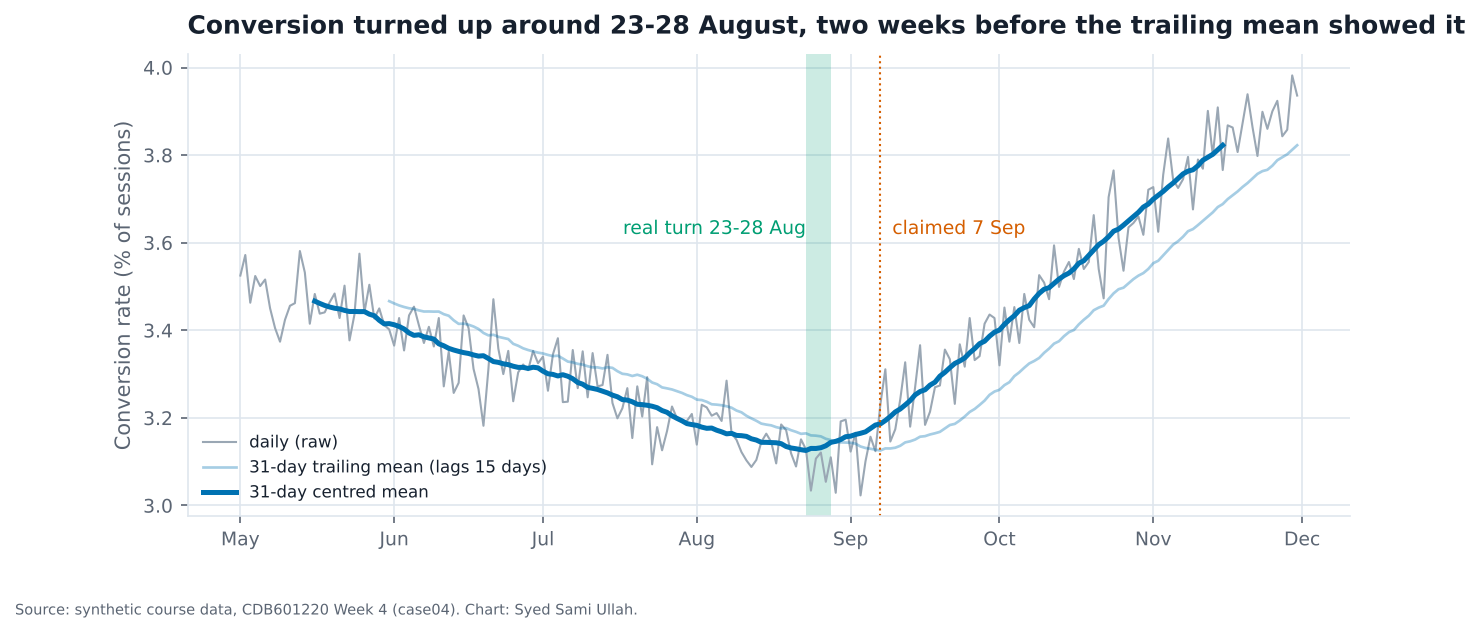

In [13]:
cent = c4.rolling(31, center=True).mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(c4.index, c4, color=GREY, lw=1, label="daily (raw)")
ax.plot(trail.index, trail, color=BLUE, lw=1.3, alpha=0.35, label="31-day trailing mean (lags 15 days)")
ax.plot(cent.index, cent, color=BLUE, lw=2.4, label="31-day centred mean")
ax.axvspan(lag["centred_turn"], hinge, color=GREEN, alpha=0.2, lw=0)
ax.text(lag["centred_turn"], 3.62, "real turn 23-28 Aug", color=GREEN, fontsize=9, ha="right")
ax.axvline(turn_t, color=ORANGE, lw=1, ls=":")
ax.text(turn_t, 3.62, "  claimed 7 Sep", color=ORANGE, fontsize=9)
ax.set_ylabel("Conversion rate (% of sessions)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_title("Conversion turned up around 23-28 August, two weeks before the trailing mean showed it")
ax.legend(loc="lower left", fontsize=8)
save(fig, "partA_case04_redesign.png", "case04")

**What the redesign shows.** The centred mean and the raw breakpoint agree on late August. If the new checkout went live on 7 September it cannot be the cause, so someone needs to check what changed in late August.

---
## Case 5 · "Revenue has fallen for six straight months"
Recipe: May to November 2025 only, line with markers, y from zero.

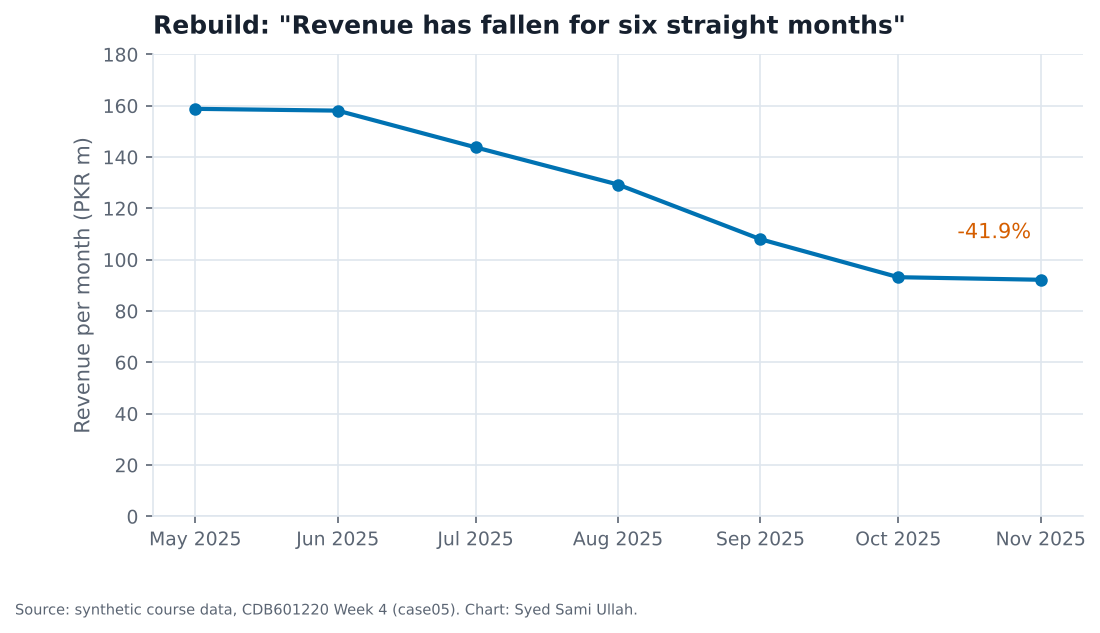

In [14]:
c5 = pd.read_csv(DATA / "case05_revenue_window.csv")
c5["date"] = pd.to_datetime(c5.month, format="%Y-%m")
c5 = c5.set_index("date").revenue_pkr_m
win = c5["2025-05":"2025-11"]
assert len(win) == 7 and win.iloc[0] == 158.8 and win.iloc[-1] == 92.2
assert round((win.iloc[-1] / win.iloc[0] - 1) * 100, 1) == -41.9

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(win.index, win, color=BLUE, marker="o")
ax.set_ylim(0, 180)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Revenue per month (PKR m)")
ax.set_title('Rebuild: "Revenue has fallen for six straight months"')
ax.annotate(f"{win.iloc[-1] / win.iloc[0] - 1:.1%}", xy=(win.index[-1], win.iloc[-1]), xytext=(-40, 20),
            textcoords="offset points", color=ORANGE)
save(fig, "partA_case05_rebuild.png", "case05")

**What this chart shows.** Six falls in a row, 158.8 down to 92.2, on an honest zero-based axis. Every point is correct; what's wrong is where the window starts and stops.

In [15]:
print(f"n available = {len(c5)} complete months ({c5.index.min():%Y-%m} to {c5.index.max():%Y-%m}); y-axis starts at 0")
for y in [2023, 2024, 2025]:
    w = c5[f"{y}-05":f"{y}-11"]
    print(f"{y}: May {w.iloc[0]:.1f} -> Nov {w.iloc[-1]:.1f}  ({w.iloc[-1] / w.iloc[0] - 1:+.1%}), peak month = {c5[str(y)].idxmax():%b}, trough = {c5[str(y)].idxmin():%b}")
yoy = (c5["2025-05":"2025-11"].values / c5["2024-05":"2024-11"].values - 1) * 100
print("2025 vs same month 2024, May-Nov:", np.round(yoy, 1).tolist())
ann = c5.groupby(c5.index.year).sum()
print("annual revenue:", ann.round(1).to_dict(), f"-> 2025 vs 2024 {ann[2025] / ann[2024] - 1:+.1%}")

n available = 36 complete months (2023-01 to 2025-12); y-axis starts at 0
2023: May 131.1 -> Nov 75.5  (-42.4%), peak month = Jun, trough = Nov
2024: May 147.5 -> Nov 84.4  (-42.8%), peak month = May, trough = Nov
2025: May 158.8 -> Nov 92.2  (-41.9%), peak month = May, trough = Nov
2025 vs same month 2024, May-Nov: [7.7, 11.5, 10.1, 12.9, 12.9, 5.9, 9.2]
annual revenue: {2023: 1254.7, 2024: 1361.9, 2025: 1496.3} -> 2025 vs 2024 +9.9%


- **Conclusion it invites:** the business is in decline.
- **Decoy:** the brief warns against two. The axis is not truncated (it starts at 0), and the sample is not small: 36 complete months exist, the analyst simply used 7 of them.
- **Mechanism:** the window starts at the seasonal peak and ends at the trough. November is the trough in all three years and May is the peak in 2024 and 2025 (June in 2023, by 1.9m), and May → Nov fell −42.4% in 2023 and −42.8% in 2024 too. Against the same months of 2024, every month in the window is *up* (+5.9% to +12.9%), and 2025 as a whole is up 9.9%.

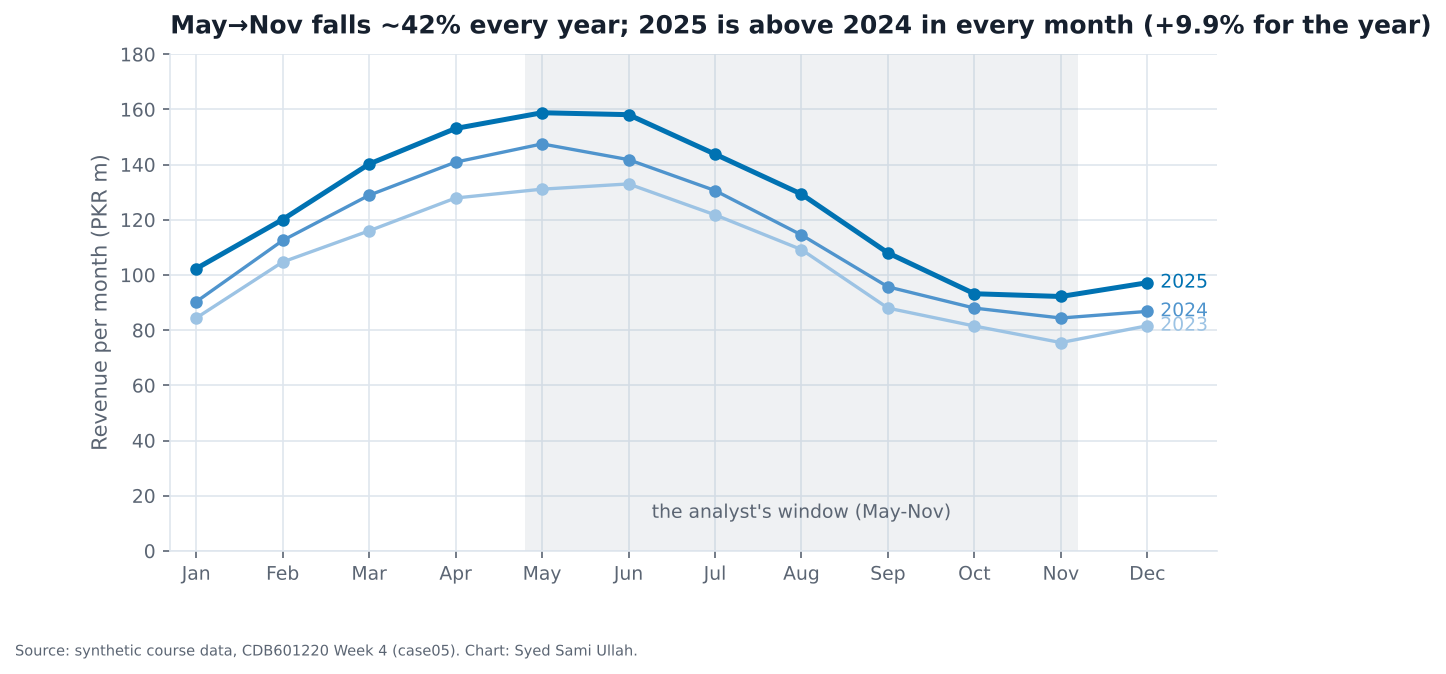

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.3))
shades = {2023: "#9CC3E4", 2024: "#4F94CD", 2025: BLUE}
for y in [2023, 2024, 2025]:
    s = c5[str(y)]
    ax.plot(s.index.month, s.values, color=shades[y], marker="o", lw=2.4 if y == 2025 else 1.6, label=str(y))
    ax.text(12.15, s.values[-1], str(y), color=shades[y], va="center", fontsize=9)
ax.axvspan(4.8, 11.2, color=GREY, alpha=0.15, lw=0)
ax.text(8, 12, "the analyst's window (May-Nov)", ha="center", color=SOFT, fontsize=9)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.7, 12.8)
ax.set_ylim(0, 180)
ax.set_ylabel("Revenue per month (PKR m)")
ax.set_title("May→Nov falls ~42% every year; 2025 is above 2024 in every month (+9.9% for the year)")
save(fig, "partA_case05_redesign.png", "case05")

**What the redesign shows.** Same line, same zero axis, with the earlier years next to it. The "six-month fall" is just the usual seasonal slide, and 2025 is the highest of the three lines the whole way through. This is one of the two cases that was incomplete rather than wrong.

---
## Case 6 · "Orders collapsed in October"
Recipe: monthly totals with `.sum()`, bars from zero.

Oct / Sep = 37%


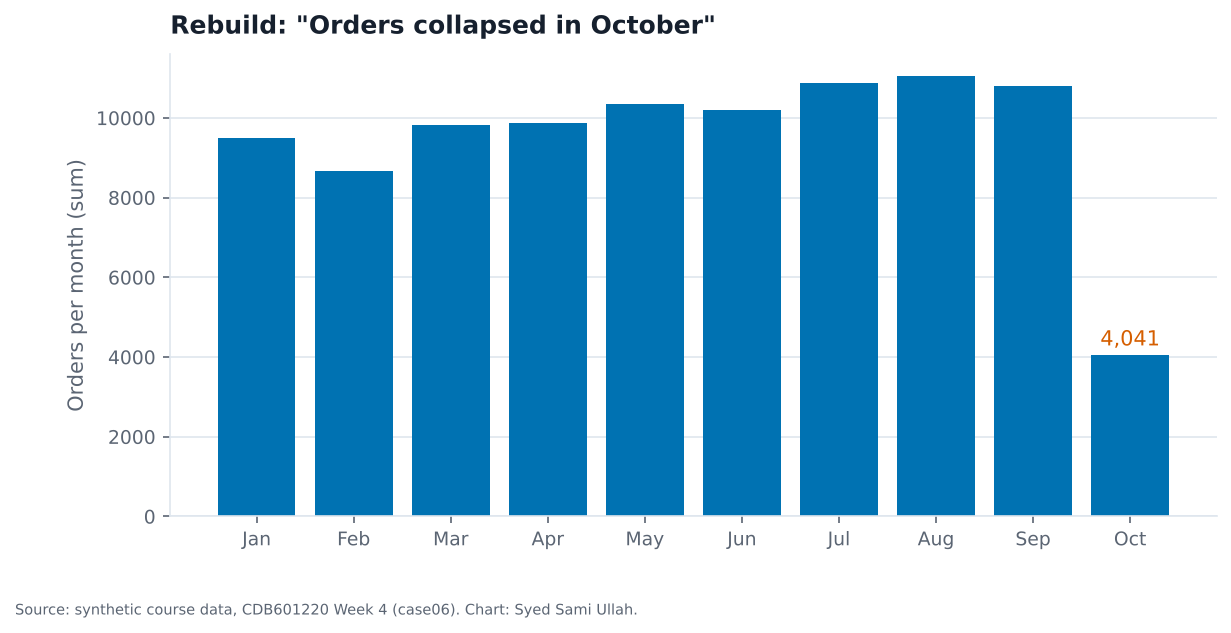

In [17]:
c6 = pd.read_csv(DATA / "case06_monthly_partial.csv", parse_dates=["date"]).set_index("date").orders
monthly = c6.resample("MS").sum()
assert len(monthly) == 10 and monthly["2025-09"].iloc[0] == 10805 and monthly["2025-10"].iloc[0] == 4041
print(f"Oct / Sep = {monthly.iloc[-1] / monthly.iloc[-2]:.0%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(monthly.index.strftime("%b"), monthly, color=BLUE)
ax.set_ylabel("Orders per month (sum)")
ax.set_title('Rebuild: "Orders collapsed in October"')
ax.text(9, monthly.iloc[-1] + 250, f"{monthly.iloc[-1]:,}", ha="center", color=ORANGE)
ax.grid(axis="x", visible=False)
save(fig, "partA_case06_rebuild.png", "case06")

**What this chart shows.** Nine bars around 9-11k and then October at 4,041, about 37% of September. A drop like that looks like a crisis.

In [18]:
a6 = tslib.audit_index(c6, "D")
print({k: a6[k] for k in ["n_rows", "n_duplicated", "n_missing", "span", "partial_tail", "tail_period", "tail_count"]})
per = c6.resample("MS").agg(["sum", "count", "mean"])
print(per.tail(3).round(1))
print("zero-order days:", (c6 == 0).sum(), "| lowest October day:", c6["2025-10"].min())
print(f"days share 11/31 = {11 / 31:.1%};  October at September's daily rate would be {per['mean'].iloc[-1] * 31:,.0f}")

{'n_rows': 284, 'n_duplicated': 0, 'n_missing': 0, 'span': ('2025-01-01 00:00:00', '2025-10-11 00:00:00'), 'partial_tail': True, 'tail_period': '2025-10', 'tail_count': 11}
              sum  count   mean
date                           
2025-08-01  11042     31  356.2
2025-09-01  10805     30  360.2
2025-10-01   4041     11  367.4
zero-order days: 0 | lowest October day: 347
days share 11/31 = 35.5%;  October at September's daily rate would be 11,388


- **Conclusion it invites:** demand fell off a cliff in October.
- **Decoy:** maybe a real outage or holiday in October. Ruled out: there are no zero days, the lowest October day is 347, and October's daily average (367.4) is *higher* than September's (360.2).
- **Mechanism:** an incomplete final period. The extract stops on 11 October (`audit_index` flags `partial_tail`, 11 rows), so October holds 11 of its 31 days. 11/31 = 35.5%, and with the slightly higher daily rate that gives the 37%. At its own pace October would be about 11,390 orders, a record.

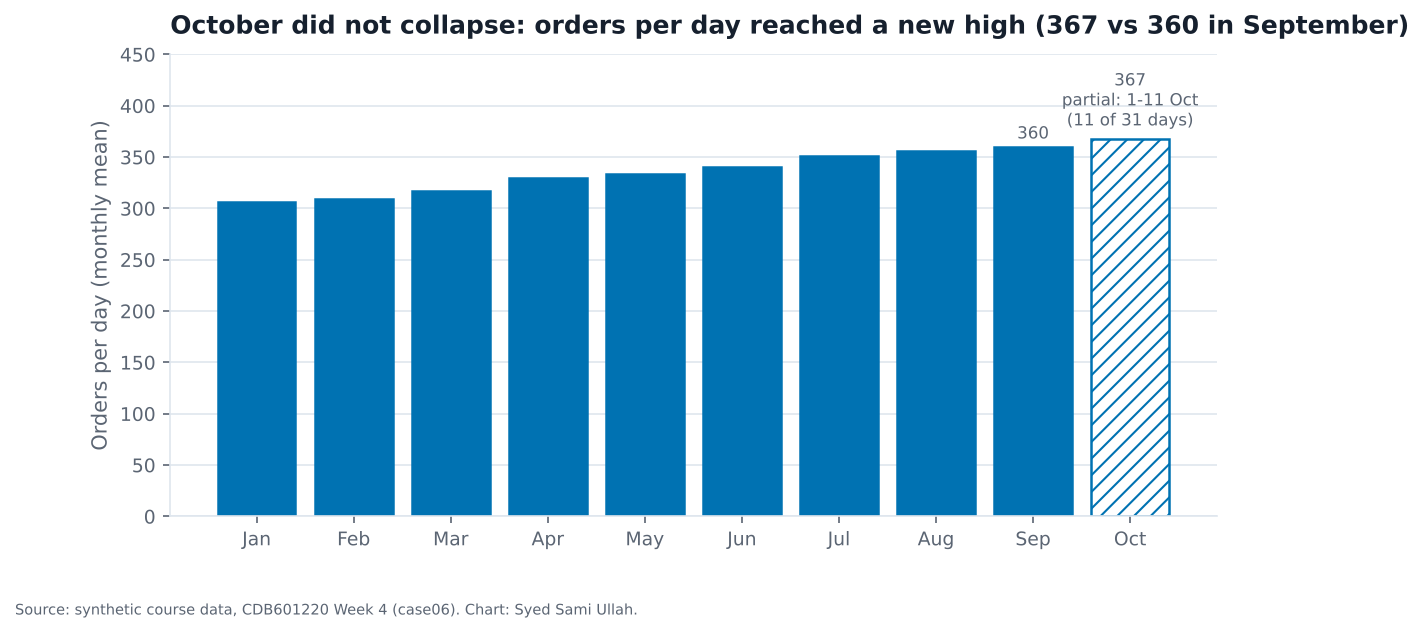

In [19]:
avg = per["mean"]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(avg.index.strftime("%b"), avg, color=[BLUE] * 9 + ["white"], edgecolor=[BLUE] * 10, hatch=[None] * 9 + ["///"], lw=1.2)
ax.text(9, avg.iloc[-1] + 8, f"{avg.iloc[-1]:.0f}\npartial: 1-11 Oct\n(11 of 31 days)", ha="center", va="bottom", fontsize=8, color=SOFT)
ax.text(8, avg.iloc[-2] + 8, f"{avg.iloc[-2]:.0f}", ha="center", fontsize=8, color=SOFT)
ax.set_ylim(0, 450)
ax.set_ylabel("Orders per day (monthly mean)")
ax.set_title("October did not collapse: orders per day reached a new high (367 vs 360 in September)")
ax.grid(axis="x", visible=False)
save(fig, "partA_case06_redesign.png", "case06")

**What the redesign shows.** Switching to orders per day makes months of different length comparable, and the hatched October bar is marked as partial. The trend is a steady climb all year, and October continues it.

---
## Case 7 · "Product D has been erratic since mid-2024"
Recipe: stacked area of the four products, `product_a` at the bottom, `product_d` on top.

envelope 548.3 to 708.7


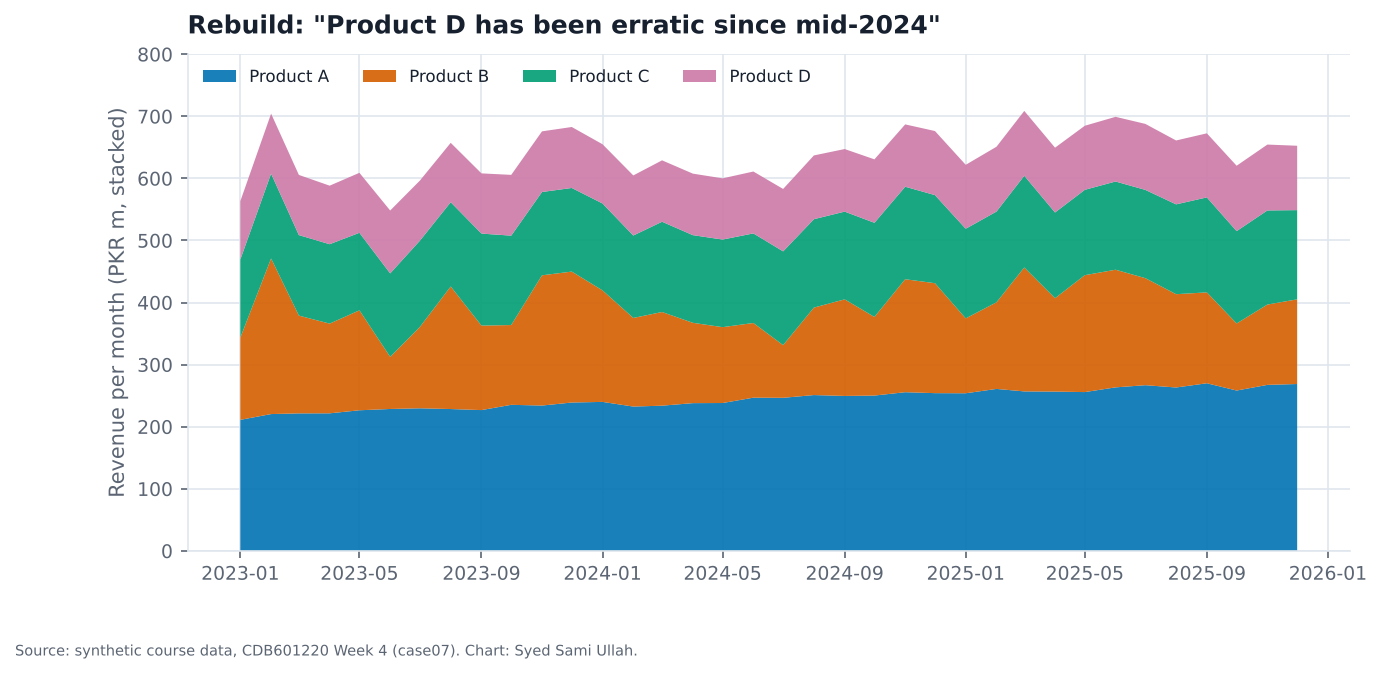

In [20]:
c7 = pd.read_csv(DATA / "case07_stacked_products.csv")
c7["date"] = pd.to_datetime(c7.month, format="%Y-%m")
c7 = c7.set_index("date").drop(columns="month")
total = c7.sum(axis=1)
assert abs(total.min() - 548) < 1 and abs(total.max() - 709) < 1
print(f"envelope {total.min():.1f} to {total.max():.1f}")

cols4 = [BLUE, ORANGE, GREEN, PINK]
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.stackplot(c7.index, *[c7[c] for c in c7.columns], labels=[c.replace("_", " ").title() for c in c7.columns], colors=cols4, alpha=0.9)
ax.set_ylabel("Revenue per month (PKR m, stacked)")
ax.set_title('Rebuild: "Product D has been erratic since mid-2024"')
ax.legend(loc="upper left", ncol=4, fontsize=8)
ax.set_ylim(0, 800)
save(fig, "partA_case07_rebuild.png", "case07")

**What this chart shows.** The top band (D) has the most jagged edge on the chart, so it reads as the unstable product. But the top edge of D is the total of all four, not D.

In [21]:
stats7 = pd.DataFrame({
    "mean": c7.mean(), "sd": c7.std(), "sd of monthly change": c7.diff().std(),
    "change sd up to Jun-24": c7[:"2024-06"].diff().std(), "change sd from Jul-24": c7["2024-07":].diff().std(),
    "min": c7.min(), "max": c7.max()}).round(1)
print(stats7.to_string())
base_d = c7[["product_a", "product_b", "product_c"]].sum(axis=1)
print(f"\nD's baseline (A+B+C): sd {base_d.std():.1f} - D's own sd {c7.product_d.std():.1f}")
print(f"corr(D's top edge, product_b) = {total.corr(c7.product_b):.2f}; corr(D's top edge, product_d) = {total.corr(c7.product_d):.2f}")

            mean    sd  sd of monthly change  change sd up to Jun-24  change sd from Jul-24    min    max
product_a  244.5  16.0                   4.7                     4.3                    5.3  211.1  270.0
product_b  152.4  35.6                  45.8                    55.3                   36.2   83.9  250.6
product_c  141.1   7.3                   6.4                     7.1                    5.8  124.9  153.0
product_d  100.3   3.6                   2.0                     2.2                    1.8   94.0  106.3

D's baseline (A+B+C): sd 39.3 - D's own sd 3.6
corr(D's top edge, product_b) = 0.79; corr(D's top edge, product_d) = 0.43


- **Conclusion it invites:** product D became unstable from mid-2024 and needs looking into.
- **Decoy:** something did change for D in mid-2024. Ruled out: D's month-to-month change SD is 2.2 before July 2024 and 1.8 after, and it never leaves 94-106. It is the steadiest of the four products.
- **Mechanism:** in a stack each band sits on a moving baseline (A+B+C), so D's band inherits everyone else's wobble. The column the recipe never isolates is `product_b`: SD 35.6, monthly change SD 45.8, swinging between 83.9 and 250.6. The top edge correlates 0.79 with B and only 0.43 with D itself.

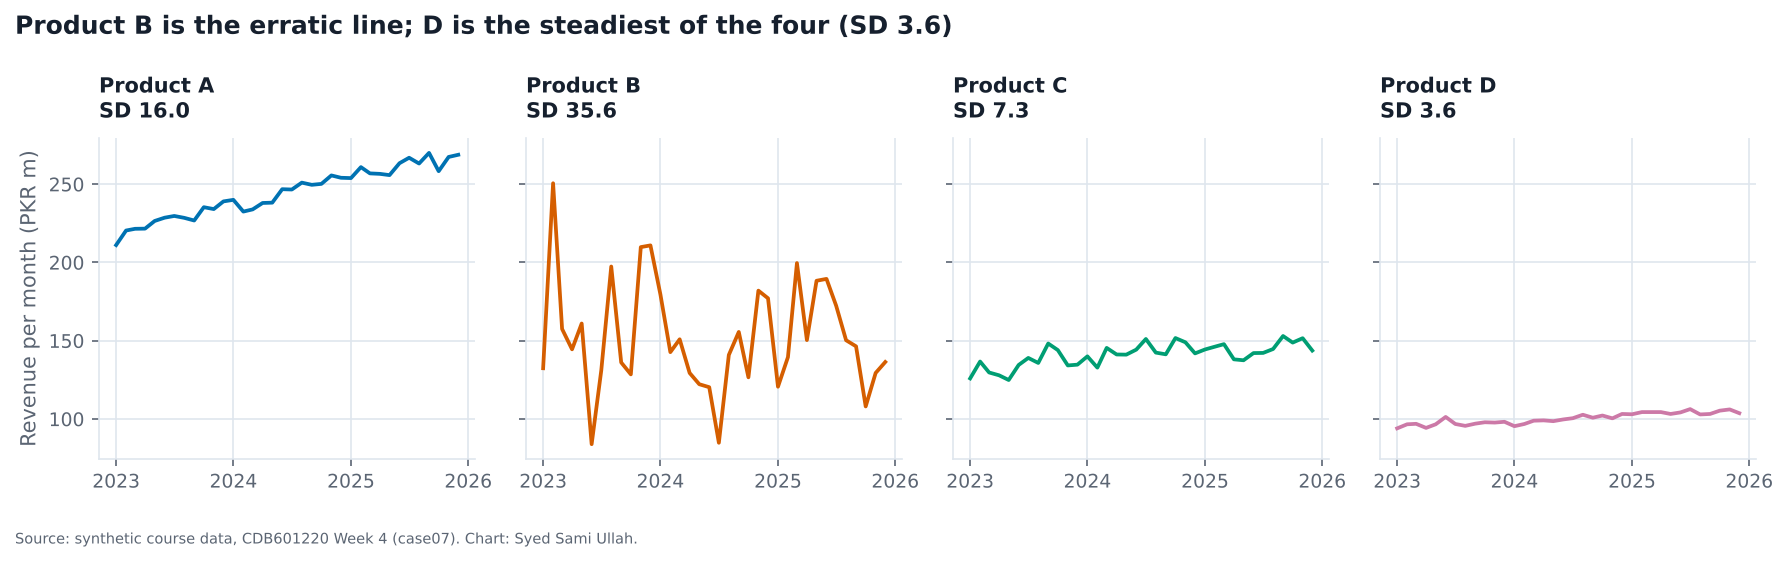

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, c, col in zip(axes, c7.columns, cols4):
    ax.plot(c7.index, c7[c], color=col, lw=1.8)
    ax.set_title(f"{c.replace('_', ' ').title()}\nSD {c7[c].std():.1f}", fontsize=10, loc="left")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("Revenue per month (PKR m)")
fig.suptitle("Product B is the erratic line; D is the steadiest of the four (SD 3.6)", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "partA_case07_redesign.png", "case07")

**What the redesign shows.** Unstacked into small multiples, each product sits on its own flat baseline with a shared y scale. D is an almost straight line, and all the noise belongs to B.

---
## Case 8 · "Paid search drives 43% of our customers"
Recipe: count `True` in each `touch_*` column, divide by customers, four-slice pie.

{'touch_search': 42.6, 'touch_social': 32.3, 'touch_email': 27.5, 'touch_direct': 28.6} sum = 131.0


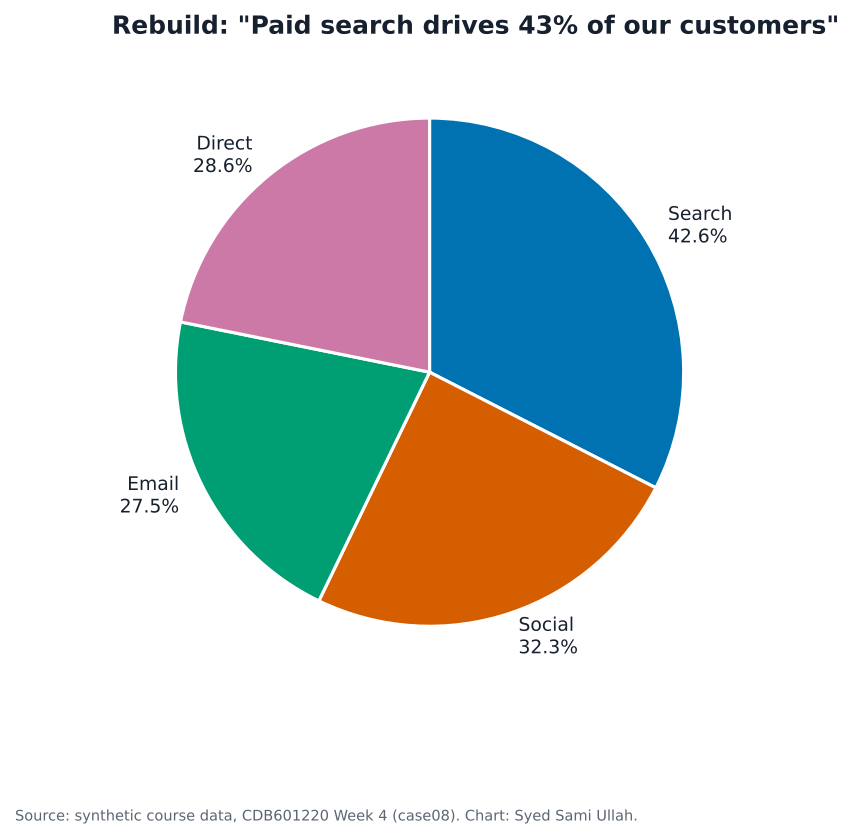

In [23]:
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
touch = [c for c in c8.columns if c.startswith("touch_")]
shares8 = (c8[touch].sum() / len(c8) * 100).round(1)
assert shares8.to_dict() == {"touch_search": 42.6, "touch_social": 32.3, "touch_email": 27.5, "touch_direct": 28.6}
print(shares8.to_dict(), "sum =", round(shares8.sum(), 1))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
names = [t.replace("touch_", "").title() for t in touch]
ax.pie(shares8, labels=[f"{n}\n{v}%" for n, v in zip(names, shares8)], colors=cols4, startangle=90,
       counterclock=False, wedgeprops=dict(edgecolor="white", linewidth=1.5))
ax.set_title('Rebuild: "Paid search drives 43% of our customers"')
save(fig, "partA_case08_rebuild.png", "case08")

**What this chart shows.** Search looks like the biggest slice and its label says 42.6%. Add the four labels and you get 131%, so this can't be a whole.

In [24]:
ex = tslib.exclusivity_check(c8, touch)
print(ex)
print("rows:", len(c8), "| unique customer_id:", c8.customer_id.nunique())
n_touch = c8[touch].sum(axis=1)
print("channels per customer:", n_touch.value_counts().sort_index().to_dict())
search_slice = shares8["touch_search"] / shares8.sum() * 100
print(f"what the pie actually draws for search: {search_slice:.1f}% of the circle, labelled 42.6%")
only = {t.replace("touch_", ""): round(((c8[t]) & (n_touch == 1)).mean() * 100, 1) for t in touch}
only["2+ channels"] = round((n_touch >= 2).mean() * 100, 1)
print("exclusive groups (%):", only, "sum =", round(sum(only.values()), 1))

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
rows: 4000 | unique customer_id: 4000
channels per customer: {1: 2895, 2: 980, 3: 116, 4: 9}
what the pie actually draws for search: 32.5% of the circle, labelled 42.6%
exclusive groups (%): {'search': np.float64(25.9), 'social': np.float64(17.8), 'email': np.float64(13.8), 'direct': np.float64(14.8), '2+ channels': np.float64(27.6)} sum = 99.9


- **Conclusion it invites:** search is the channel behind 43% of customers, so it deserves the biggest budget.
- **Decoy:** maybe customers are double-counted as duplicate rows. Ruled out: 4,000 rows and 4,000 unique `customer_id`s.
- **Mechanism:** the parts are not exclusive. 1,105 customers (27.6%) were touched by two or more channels, so the four shares sum to 131.0%. A pie silently re-normalises, so search's wedge is really 32.5% of the circle while its label says 42.6%. "Touched" is also not "drove": only 25.9% of customers came through search alone.

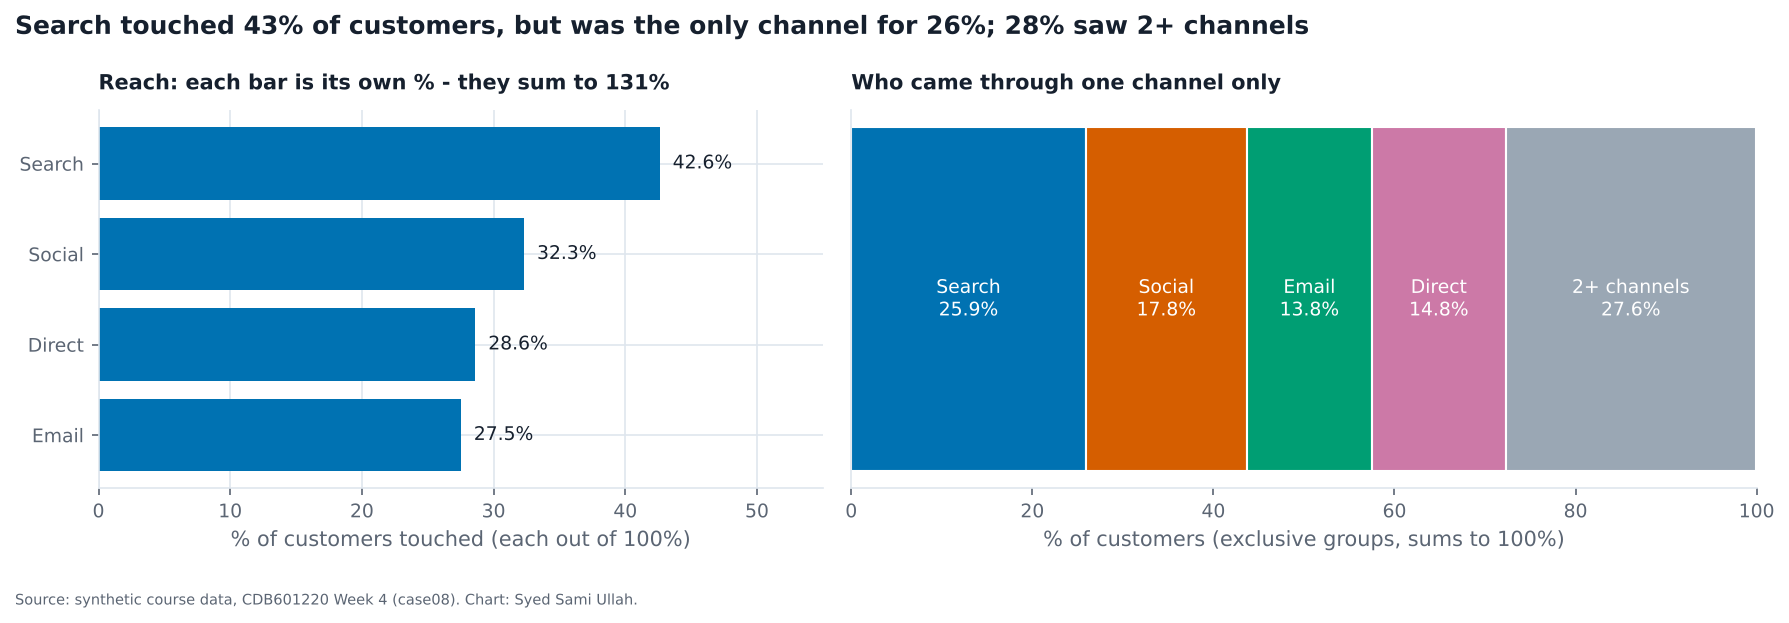

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
order = shares8.sort_values()
ax1.barh([n.replace("touch_", "").title() for n in order.index], order, color=BLUE)
for i, v in enumerate(order):
    ax1.text(v + 1, i, f"{v}%", va="center", fontsize=9)
ax1.set_xlim(0, 55)
ax1.set_xlabel("% of customers touched (each out of 100%)")
ax1.set_title("Reach: each bar is its own % - they sum to 131%", fontsize=10)
grp = pd.Series(only)
left = 0
gcols = [BLUE, ORANGE, GREEN, PINK, GREY]
for (k, v), col in zip(grp.items(), gcols):
    ax2.barh([0], [v], left=left, color=col, edgecolor="white")
    ax2.text(left + v / 2, 0, f"{k.title() if k != '2+ channels' else k}\n{v}%", ha="center", va="center", color="white", fontsize=9)
    left += v
ax2.set_xlim(0, 100)
ax2.set_yticks([])
ax2.set_xlabel("% of customers (exclusive groups, sums to 100%)")
ax2.set_title("Who came through one channel only", fontsize=10)
ax2.grid(False)
fig.suptitle("Search touched 43% of customers, but was the only channel for 26%; 28% saw 2+ channels",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "partA_case08_redesign.png", "case08")

**What the redesign shows.** Reach is shown as separate bars (not a whole), and the real part-to-whole is the exclusive split on the right, which adds to 100%. Search is still the largest single channel, but at 26%, not 43%.

---
## Case 9 · "Premium is now 38% of revenue - a record"
Recipe: premium / total per quarter, line, y from zero, annotate the last point.

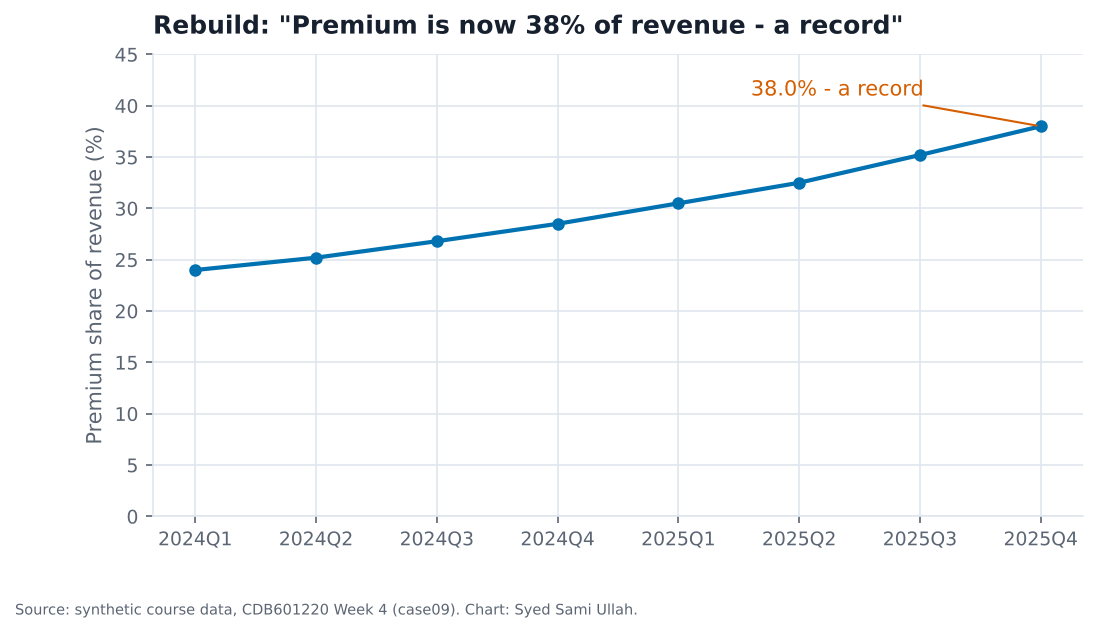

In [26]:
c9 = pd.read_csv(DATA / "case09_premium_share.csv")
c9["share"] = c9.premium_revenue_pkr_m / c9.total_revenue_pkr_m * 100
assert round(c9.share.iloc[0], 1) == 24.0 and round(c9.share.iloc[-1], 1) == 38.0

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(c9.quarter, c9.share, color=BLUE, marker="o")
ax.set_ylim(0, 45)
ax.annotate(f"{c9.share.iloc[-1]:.1f}% - a record", xy=(7, c9.share.iloc[-1]), xytext=(4.6, 41), color=ORANGE,
            arrowprops=dict(arrowstyle="-", color=ORANGE))
ax.set_ylabel("Premium share of revenue (%)")
ax.set_title('Rebuild: "Premium is now 38% of revenue - a record"')
save(fig, "partA_case09_rebuild.png", "case09")

**What this chart shows.** A clean rise from 24% to 38% over eight quarters. A share is a ratio, and the chart gives no hint whether the top or the bottom of the ratio moved.

In [27]:
c9["other"] = c9.total_revenue_pkr_m - c9.premium_revenue_pkr_m
print(c9.round(1).to_string(index=False))
print("parts legal? premium <= total every quarter:", bool((c9.premium_revenue_pkr_m <= c9.total_revenue_pkr_m).all()),
      "| other > 0:", bool((c9.other > 0).all()))
for col in ["total_revenue_pkr_m", "premium_revenue_pkr_m", "other"]:
    print(f"{col:24s} {c9[col].iloc[0]:7.1f} -> {c9[col].iloc[-1]:7.1f}  ({c9[col].iloc[-1] / c9[col].iloc[0] - 1:+.1%})")

quarter  total_revenue_pkr_m  premium_revenue_pkr_m  share  other
 2024Q1               1000.0                  240.0   24.0  760.0
 2024Q2                940.0                  236.9   25.2  703.1
 2024Q3                870.0                  233.2   26.8  636.8
 2024Q4                800.0                  228.0   28.5  572.0
 2025Q1                745.0                  227.2   30.5  517.8
 2025Q2                700.0                  227.5   32.5  472.5
 2025Q3                650.0                  228.8   35.2  421.2
 2025Q4                600.0                  228.0   38.0  372.0
parts legal? premium <= total every quarter: True | other > 0: True
total_revenue_pkr_m       1000.0 ->   600.0  (-40.0%)
premium_revenue_pkr_m      240.0 ->   228.0  (-5.0%)
other                      760.0 ->   372.0  (-51.1%)


- **Conclusion it invites:** premium is booming and should get more investment.
- **Decoy:** maybe the share is computed wrong or the parts don't fit the whole. Ruled out: premium is below total in every quarter and "other" is positive, so the share is arithmetically correct.
- **Mechanism:** a rising share of a falling total. Total revenue fell 40% (1,000 → 600) and the non-premium part fell 51% (760 → 372). Premium revenue itself went *down* 5% (240 → 228). The record share is entirely the denominator shrinking.

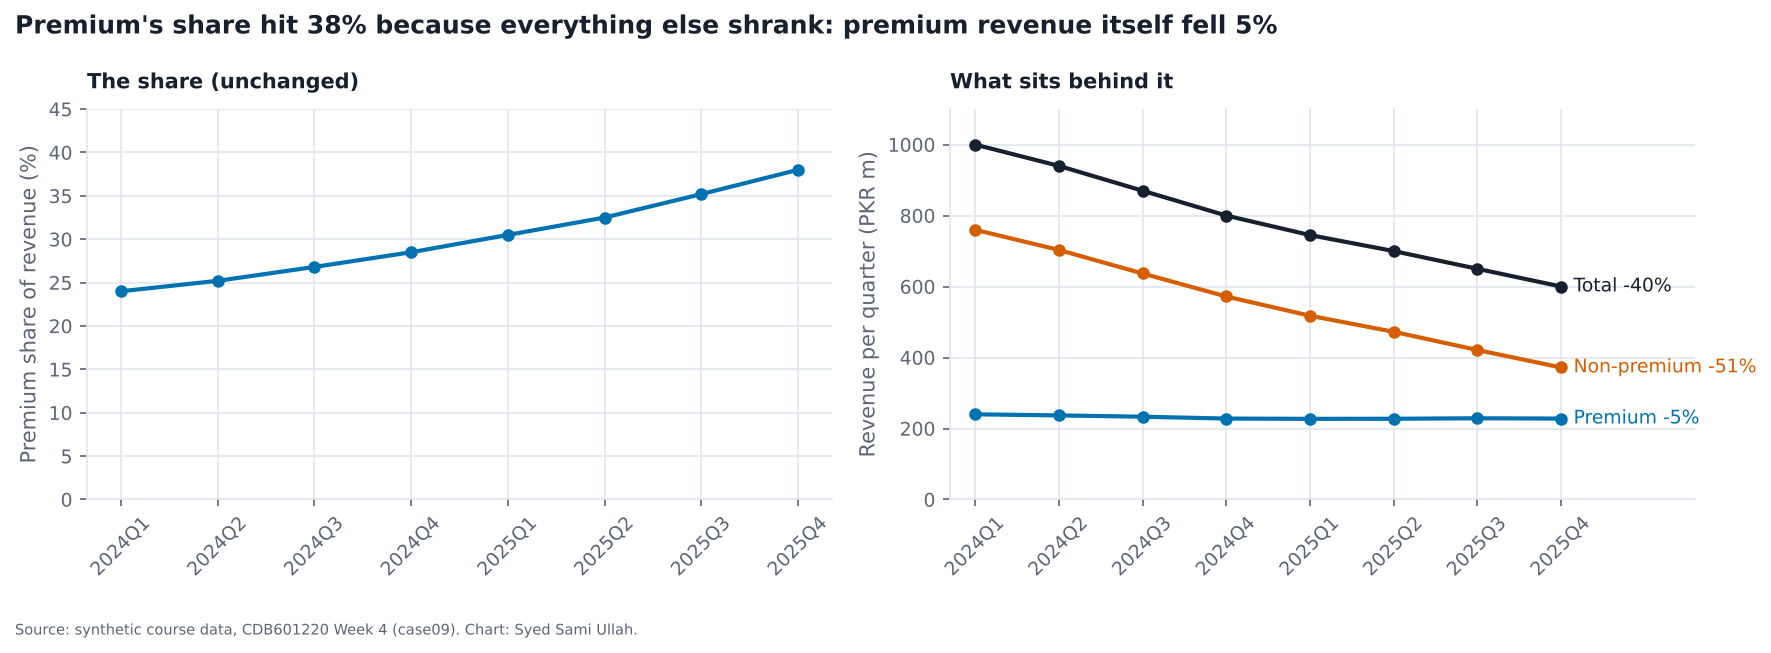

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(c9.quarter, c9.share, color=BLUE, marker="o")
ax1.set_ylim(0, 45)
ax1.set_ylabel("Premium share of revenue (%)")
ax1.set_title("The share (unchanged)", fontsize=10)
ax1.tick_params(axis="x", rotation=45)
for col, colr, lab in [("total_revenue_pkr_m", INK, "Total"), ("other", ORANGE, "Non-premium"), ("premium_revenue_pkr_m", BLUE, "Premium")]:
    ax2.plot(c9.quarter, c9[col], color=colr, marker="o", lw=2)
    ax2.text(7.15, c9[col].iloc[-1], f"{lab} {c9[col].iloc[-1] / c9[col].iloc[0] - 1:+.0%}", color=colr, va="center", fontsize=9)
ax2.set_ylim(0, 1100)
ax2.set_xlim(-0.3, 8.6)
ax2.set_ylabel("Revenue per quarter (PKR m)")
ax2.set_title("What sits behind it", fontsize=10)
ax2.tick_params(axis="x", rotation=45)
fig.suptitle("Premium's share hit 38% because everything else shrank: premium revenue itself fell 5%",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "partA_case09_redesign.png", "case09")

**What the redesign shows.** The same share line, with the absolute revenue next to it. Premium is flat-to-falling while total revenue lost 40%, which is a much worse story than "a record". This is the second incomplete-not-wrong case.

---
## Summary

| # | Self-check | Mechanism | Number that proves it |
|---|---|---|---|
| 1 | −958, −978 ✓ | dates sorted as text | 23/23 real monthly changes positive |
| 2 | 207 → 253, +22% ✓ | row number as x hides 21 closed days | slopes ≈ 0 both sides, one step +28.6% |
| 3 | 8,800 → 12,500 ✓ | a level resampled with `sum()` | June 16.4 hours/day vs 24; mean −2.5% |
| 4 | min on 7 Sep ✓ | trailing mean lags half a window | 15 days; real turn 23-28 Aug |
| 5 | 158.8 → 92.2 ✓ | window starts at the seasonal peak | May→Nov −42% every year; 2025 +9.9% |
| 6 | 10,805 / 4,041 ✓ | incomplete final period | October has 11 of 31 days |
| 7 | 548-709 ✓ | moving baseline in a stack | D's SD 3.6, B's SD 35.6 |
| 8 | 42.6/32.3/27.5/28.6 ✓ | parts not exclusive | sum 131%, 27.6% multi-touch |
| 9 | 24% → 38% ✓ | rising share of a falling total | premium −5%, total −40% |